# Solar filament instance segmentation — full pipeline

This notebook runs the complete pipeline used for our submission to the
**Solar Filament Segmentation Challenge 2026** (IEEE BigData Cup, NSF NSO):

1. **Data** — the MAGFiLO training annotations and how much the annotators agree with each other;
2. **Training** — an ensemble of U-Nets with modern pretrained encoders (EfficientNetV2-S, ConvNeXt-T at 1024 and
   1536 px, ConvNeXt-S) trained on the *per-pixel annotator agreement*, 5-fold cross-validation;
3. **From probabilities to filaments** — (a) simple tuned rules, (b) a *PQ-optimal decision layer* (analysis) and
   (c) an *instance refiner* that redraws each filament in its own crop;
4. **Validation report** — PQ / SQ / RQ, the organisers' IoU / Dice / 1:n / n:1 analysis, error analysis;
5. **Test inference** — the submission file for the 180 test images, with the compute cost per image.

`MODE = "full"` runs the submitted pipeline (`weights/final_config.json`: 20 U-Nets = EfficientNetV2-S and
ConvNeXt-T at 1024 px, ConvNeXt-T at 1536 px and ConvNeXt-S, 5 folds each, plus tuned rules and the instance refiner;
out-of-fold PQ 0.443, public leaderboard 0.39); `MODE = "fast"` runs the 10-model version (`weights/fast_config.json`,
EfficientNetV2-S + ConvNeXt-T; out-of-fold PQ 0.442) at less than half the cost.

All logic lives in the `filament_seg` package; this notebook only orchestrates it and explains each step. It runs
unchanged on a local checkout and as a Kaggle notebook (the first cell sets up Kaggle's input folders).

**Runtime.** With `TRAIN = False` (default) the notebook uses the trained weights in `weights/`; on a laptop
(RTX 3070 Ti 8 GB) the full pipeline takes about 1–1.5 hours (most of it out-of-fold inference of every ensemble
member with 8-view TTA), on a Kaggle T4 about twice as long. With `TRAIN = True` it retrains every fold first
(45–120 minutes per fold); with `RUN_TUNING = True` it also re-fits the post-processing, the decision layer and the
refiner (~1 hour).

In [1]:
# Kaggle setup (does nothing on a local checkout): installs the two pinned packages, copies the `filament_seg`
# code, links the trained weights and points the data path at the competition input.  Large intermediate files
# go to /tmp so they do not count against Kaggle's 20 GB output limit.
import os, sys, glob, shutil, subprocess
from pathlib import Path

if Path("/kaggle/input").exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch==0.6.0",
                    "timm==1.0.31", "pycocotools"], check=True)
    repo = Path("/kaggle/working/repo")
    pkg = Path(glob.glob("/kaggle/input/**/filament_seg/__init__.py", recursive=True)[0]).parent
    shutil.copytree(pkg, repo / "filament_seg", dirs_exist_ok=True)
    for script in glob.glob("/kaggle/input/**/report/official_eval.py", recursive=True)[:1]:
        (repo / "report").mkdir(parents=True, exist_ok=True)
        shutil.copy(script, repo / "report" / "official_eval.py")
    wsrc = Path(glob.glob("/kaggle/input/**/final_config.json", recursive=True)[0]).parent
    (repo / "weights").mkdir(parents=True, exist_ok=True)
    for f in wsrc.iterdir():
        if not (repo / "weights" / f.name).exists():
            os.symlink(f, repo / "weights" / f.name)
    Path("/tmp/work").mkdir(parents=True, exist_ok=True)
    if not (repo / "work").exists():
        os.symlink("/tmp/work", repo / "work")
    ann = glob.glob("/kaggle/input/**/MAGFiLO_1.0_Annotations_kaggle2026_train.json", recursive=True)[0]
    os.environ["FILAMENT_DATA_ROOT"] = str(Path(ann).parent.parent)
    os.chdir(repo)
    print("Kaggle setup done:", repo, "| data:", os.environ["FILAMENT_DATA_ROOT"], "| weights:", wsrc)

In [2]:
import os, sys, json, time, shutil
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")  # keep the saved notebook free of progress-bar noise

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import pickle

from filament_seg import paths, train, tune, predict, rle, decision_train
from filament_seg.annotations import load_annotations, label_map, consensus_mask, make_folds
from filament_seg.decision import decide_image
from filament_seg.evaluation import DecisionLabeler, evaluate_detailed, prob_loader
from filament_seg.imaging import read_gray
from filament_seg.inference import predict_to_dir
from filament_seg.metrics import PQAccumulator
from filament_seg.model import load_checkpoint
from filament_seg.postprocess import PostprocessParams, probs_to_labels
from filament_seg.visualize import outlines, bounding_box, PALETTE

from filament_seg.blend import blend_dirs, load_config

# ---------------- configuration ----------------
MODE = "full"         # "full": the submitted pipeline (weights/final_config.json)
                      # "fast": a small ensemble for low compute (weights/fast_config.json)
TRAIN = False         # True: retrain every fold of every ensemble member (~45-90 min per fold)
RUN_TUNING = False    # True: re-fit rules, decision layer and refiner on the out-of-fold predictions
N_FOLDS, SEED = 5, 42
FOLDS = [0, 1, 2, 3, 4]
WORKERS = 4           # CPU processes for evaluation / decision-layer bank

CFG = load_config(paths.WEIGHTS_DIR / ("final_config.json" if MODE == "full" else "fast_config.json"))
TTA = CFG["tta"]      # "d4": 8 views (flips x transpose); +0.002 PQ over 4 flips
# training recipe of every possible ensemble member (run name = <arch prefix><encoder>_s<size>)
TRAIN_ARGS = {
    "resnet34_s1024": dict(size=1024, encoder="resnet34", arch="unet", epochs=40, batch_size=4, lr=5e-4),
    "resnet34_s1536": dict(size=1536, encoder="resnet34", arch="unet", epochs=40, batch_size=2, lr=3.5e-4),
    "unetplusplus_resnet34_s1024": dict(size=1024, encoder="resnet34", arch="unetplusplus", epochs=40, batch_size=2, lr=3.5e-4),
    "unetplusplus_resnet34_s1536": dict(size=1536, encoder="resnet34", arch="unetplusplus", epochs=30, batch_size=2, lr=3.5e-4),
    "tu-tf_efficientnetv2_s_s1024": dict(size=1024, encoder="tu-tf_efficientnetv2_s", arch="unet", epochs=40, batch_size=4, lr=5e-4),
    "tu-convnext_tiny_s1024": dict(size=1024, encoder="tu-convnext_tiny", arch="unet", epochs=40, batch_size=2, lr=2.5e-4),
    # folds 0-3 on Kaggle GPUs; fold 4 of the 1536-px ConvNeXt-T on an 8 GB laptop GPU with batch 1, lr 1.8e-4
    "tu-convnext_tiny_s1536": dict(size=1536, encoder="tu-convnext_tiny", arch="unet", epochs=30, batch_size=2, lr=2.5e-4),
    "tu-convnext_small_s1024": dict(size=1024, encoder="tu-convnext_small", arch="unet", epochs=40, batch_size=2, lr=2e-4),
}
MEMBERS = [m for g in CFG["groups"] for m in g["members"]]
WEIGHTS = {(m, f): paths.WEIGHTS_DIR / f"{m}_f{f}.pt" for m in MEMBERS for f in FOLDS}
PARAMS_FILE = Path(CFG["params"])
REFINER_FILE = Path(CFG["refiner"]) if CFG.get("refiner") else None
DECISION_FILE = paths.WEIGHTS_DIR / "decision.pkl"
OOF_DIR = paths.WORK_DIR / "oof" / f"pipeline_{MODE}_{TTA}"
SUBMISSION = ROOT / f"submission_{MODE}.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu")
print("data:", paths.DATA_ROOT)
print("pipeline:", CFG["name"])
for g in CFG["groups"]:
    print(f"  group {g['name']:12s} weight {g['weight']:<5} members {g['members']}")

D:\Kaggle Solar Filament Segmentation Challenge 2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.9.1+cu128 | device: NVIDIA GeForce RTX 3070 Ti Laptop GPU
data: D:\Kaggle Solar Filament Segmentation Challenge 2026\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026
pipeline: H: FR + cnx1536 + cnxs
  group effv2        weight 1.0   members ['tu-tf_efficientnetv2_s_s1024']
  group convnext     weight 1.0   members ['tu-convnext_tiny_s1024']
  group cnx1536      weight 4.0   members ['tu-convnext_tiny_s1536']
  group cnxs         weight 0.5   members ['tu-convnext_small_s1024']


## 1. Data

Each training image is a 2048 × 2048 GONG H-alpha observation. 296 of the 707 physical images were annotated
independently by 2–3 annotators; every annotation set is a separate COCO "image" whose id is
`<annotator>-<file stem>`. We therefore organise everything by physical image and keep each annotator's
filaments separate. Polygons are rasterised with **pycocotools**, the tool the organisers used for the
reference `area` field (OpenCV's `fillPoly` makes masks ~11% too large).

In [3]:
items = load_annotations(paths.TRAIN_JSON)
folds = make_folds(items, N_FOLDS, SEED)
n_sets = sum(it.n_annotators for it in items)
n_fil = sum(len(f) for it in items for f in it.annotations.values())
areas = np.array([fil.mask_crop()[2].sum() for it in items for f in it.annotations.values() for fil in f])
print(f"physical images: {len(items)} | annotation sets: {n_sets} | filaments: {n_fil}")
print("annotators per image:", pd.Series([it.n_annotators for it in items]).value_counts().sort_index().to_dict())
print("images per fold:", np.bincount(folds).tolist())
print("filament area (px): " + ", ".join(f"p{q}={np.percentile(areas, q):.0f}" for q in (5, 25, 50, 75, 95)))

physical images: 707 | annotation sets: 1154 | filaments: 8199
annotators per image: {1: 411, 2: 145, 3: 151}
images per fold: [142, 142, 141, 141, 141]
filament area (px): p5=317, p25=670, p50=1228, p75=2438, p95=6947


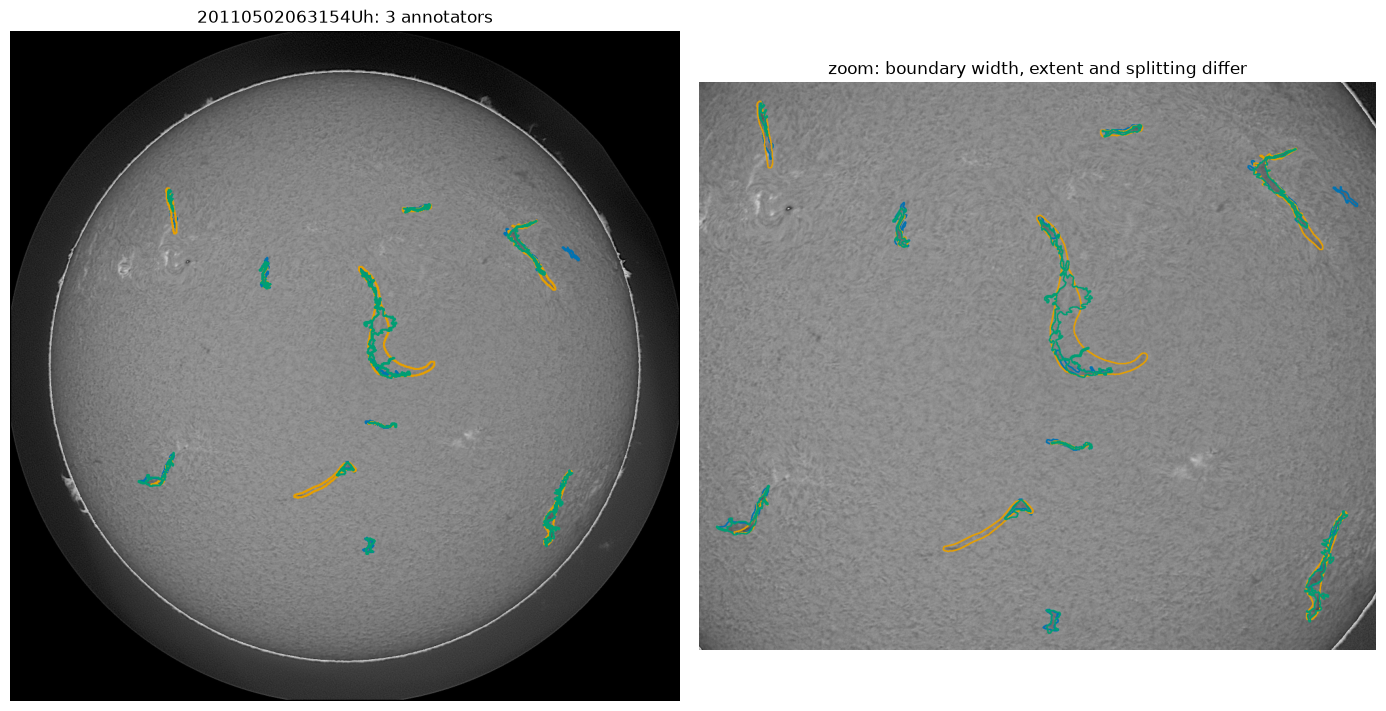

In [4]:
# one image annotated by three people: each colour is one annotator
example = next(it for it in items if it.n_annotators == 3 and sum(len(f) for f in it.annotations.values()) > 20)
img = read_gray(paths.TRAIN_IMAGES / example.file_name)
maps = [label_map(f) for f in example.annotations.values()]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(outlines(img, maps, scale=0.5)); ax[0].set_title(f"{example.stem}: 3 annotators")
ax[1].imshow(outlines(img, maps, scale=1.0, box=bounding_box(maps[:1], margin=40)))
ax[1].set_title("zoom: boundary width, extent and splitting differ")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. How much do the annotators agree?

Scoring one annotator's filaments against another's with the competition metric (PQ, IoU > 0.5 matching)
gives a human reference level. Disagreement comes from boundary width, which faint filaments are included,
and whether a long filament is one instance or several.

In [5]:
from itertools import combinations

human = PQAccumulator()
for it in items:
    if it.n_annotators > 1:
        lmaps = [label_map(f) for f in it.annotations.values()]
        for a, b in combinations(lmaps, 2):
            human.update(a, b)
human_summary = human.summary()
pd.DataFrame([human_summary]).round(3)[["PQ", "SQ", "RQ", "Dice_image_mean", "TP", "FP", "FN", "one_to_many", "many_to_one"]]

,PQ,SQ,RQ,Dice_image_mean,TP,FP,FN,one_to_many,many_to_one
0,0.34,0.634,0.536,0.614,2144,1851,1860,117,136


## 3. Training target: per-pixel annotator agreement

Instead of choosing one annotator per image, the network is trained on the fraction of annotators that marked
each pixel (0, 1/3, 1/2, 2/3, 1). This is the expected label under a randomly chosen annotator — exactly what a
per-annotator PQ evaluation rewards. Loss: BCE (works with soft targets) + batch soft-Dice (class imbalance:
filaments cover ~0.3% of the image).

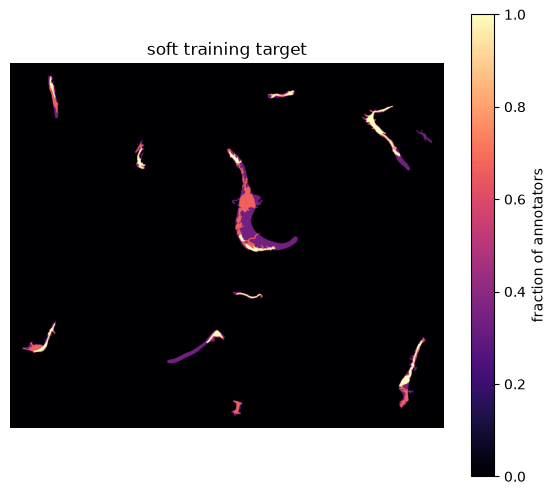

In [6]:
agreement = consensus_mask(example)
x0, y0, x1, y1 = bounding_box(maps, margin=40)
plt.figure(figsize=(7, 6))
plt.imshow(agreement[y0:y1, x0:x1], cmap="magma"); plt.colorbar(label="fraction of annotators")
plt.title("soft training target"); plt.axis("off"); plt.show()

## 4. Model and training

* **Network:** U-Net (`segmentation_models_pytorch`), 1 input channel, 1 output logit, with ImageNet-pretrained
  encoders from timm (all weights Apache-2.0 / BSD; non-commercial encoders such as SegFormer/MiT are not used).
  The submitted ensemble: EfficientNetV2-S and ConvNeXt-T at 1024 px, ConvNeXt-T at 1536 px and ConvNeXt-S at
  1024 px, 5 folds each; group weights chosen out of fold (`weights/final_config.json`). ResNet-34 U-Nets and UNet++
  were explored as well (`TRAIN_ARGS` lists every recipe) but did not help the final pipeline.
* **Input:** the full solar disk resized to 1024 × 1024 or 1536 × 1536 (filaments are ~13 px wide at native
  resolution, ~6 px at 1024).
* **Augmentation:** rotation about the disk centre by any angle, flips, ±10% scale, small shifts,
  brightness / contrast / gamma, occasional blur and noise.
* **Optimisation:** AdamW (weight decay 1e-4), 1-epoch warm-up + cosine decay, 30–40 epochs, mixed precision (bf16 on
  the laptop, fp16 on Kaggle's T4); learning rates and batch sizes per model in `TRAIN_ARGS`.
* **Validation:** 5 folds split by physical image (never by annotation set), stratified by GONG site;
  the checkpoint with the best validation PQ is kept.

In [7]:
if TRAIN:
    for m in MEMBERS:
        a = TRAIN_ARGS[m]
        for f in FOLDS:
            train.main(["--fold", str(f), "--size", str(a["size"]), "--encoder", a["encoder"], "--arch", a["arch"],
                        "--epochs", str(a["epochs"]), "--batch-size", str(a["batch_size"]), "--lr", str(a["lr"]),
                        "--workers", "3", "--val-every", "5"])
            paths.WEIGHTS_DIR.mkdir(exist_ok=True)
            shutil.copy(paths.WORK_DIR / "runs" / f"{m}_f{f}" / "best.pt", WEIGHTS[m, f])
available = [f for f in FOLDS if all(WEIGHTS[m, f].exists() for m in MEMBERS)]
print(f"{len(MEMBERS)} members x {len(available)} folds = {len(MEMBERS) * len(available)} models")

4 members x 5 folds = 20 models


## 5. Out-of-fold predictions

Each fold model predicts the validation images it never saw, averaging the 8 symmetric views of the image (flips
and transpose). Together the folds give one honest prediction for every training image, used for tuning and for
the validation report.

In [8]:
t0 = time.time()
group_dirs = {}
for g in CFG["groups"]:  # each group: average of its members' fold-f models on the images of fold f
    group_dirs[g["name"]] = paths.WORK_DIR / "oof" / f"group_{g['name']}_{TTA}"
    for f in available:
        members = [load_checkpoint(WEIGHTS[m, f], DEVICE) for m in g["members"]]
        val_stems = [it.stem for it, k in zip(items, folds) if k == f]
        predict_to_dir(members, val_stems, paths.TRAIN_IMAGES, group_dirs[g["name"]], tta=TTA, device=DEVICE)
        del members; torch.cuda.empty_cache()
n = blend_dirs(OOF_DIR, [(g["weight"], [group_dirs[g["name"]]]) for g in CFG["groups"]])
oof_items = [it for it, k in zip(items, folds) if k in available]
fold_of = {it.stem: int(k) for it, k in zip(items, folds)}
print(f"blended out-of-fold maps for {n} images in {OOF_DIR} ({time.time() - t0:.0f} s)")

blended out-of-fold maps for 707 images in D:\Kaggle Solar Filament Segmentation Challenge 2026\work\oof\pipeline_full_d4 (1632 s)


## 6. From probabilities to filament instances

### 6a. Simple tuned rules (baseline)

1. threshold the probability map;
2. treat blobs separated by at most `merge_gap` pixels as one filament (thresholding often breaks a filament
   into beads); each instance keeps only its own pixels, so merging does not fatten masks;
3. drop instances smaller than `min_area` or with mean probability below `min_mean_prob` — but keep at least
   `min_instances` per image (every training image contains a filament).

The four numbers are chosen by grid search on the out-of-fold predictions only.

In [9]:
GRID = {"threshold": [0.4, 0.45, 0.5, 0.55], "merge_gap": [8, 16, 24, 32], "min_area": [100, 200, 300],
        "min_mean_prob": [0.75, 0.8, 0.85, 0.9], "min_instances": [1]}
if RUN_TUNING:
    tune.main(["--prob-dirs", str(OOF_DIR), "--workers", str(WORKERS), "--grid", json.dumps(GRID),
               "--out", str(PARAMS_FILE)])
params = PostprocessParams(**json.loads(PARAMS_FILE.read_text()))
params

PostprocessParams(threshold=0.5, merge_gap=16, min_area=300, min_mean_prob=0.85, min_instances=1)

### 6b. PQ-optimal decision layer

For one annotator record, $TP + FP = |P|$ and $TP + FN = |G|$, so the PQ denominator $TP + \tfrac12 FP + \tfrac12 FN$
equals $\tfrac12(|P| + |G|)$: **every predicted filament adds exactly 1/2 to the denominator, matched or not**, and
adds its IoU to the numerator only if it matches (IoU > 0.5). Pooled over annotators, keeping a candidate $c$ pays
off exactly when its *annotator-expected matched IoU* $u(c)$ exceeds $\mathrm{PQ}^*/2$ (Dinkelbach's argument for
ratio objectives).

* **Candidates:** connected components of the probability map at 17 thresholds (0.10 ... 0.90), with fragments
  within 16 px grouped. Components at a higher threshold lie inside one component at the level below, so they form
  a tree; any set of nodes without ancestor-descendant pairs is a valid, pixel-disjoint submission.
* **Scorer:** gradient-boosted trees predict $u(c)$ from 24 candidate features (size, shape, confidence, contrast
  with the surrounding ring, position on the disk, stability across levels) as
  $P(\text{matched}) \times E[\mathrm{IoU} \mid \text{matched}]$. It is cross-fitted: each fold is scored by a
  model trained on the other folds' out-of-fold candidates.
* **Selection:** the best tree cut maximising $\sum (u - \tau)$ is found exactly by dynamic programming;
  $\tau \approx \mathrm{PQ}/2$ is tuned on the out-of-fold bank.

The exact pooled PQ of any selection follows from per-candidate sums stored once (the "bank"), so tuning needs no
re-rasterisation. Idea credit: the public notebook *Deciding under disagreement* (Kaggle user tushhaaarrrr);
this is an independent implementation.

In [10]:
if RUN_TUNING:
    decision_train.main(["--prob-dirs", str(OOF_DIR), "--merge-gap", "16", "--workers", str(WORKERS),
                         "--bank", str(paths.WORK_DIR / "decision" / f"bank_{MODE}_{TTA}.pkl"),
                         "--out", str(DECISION_FILE)])
decision = pickle.loads(DECISION_FILE.read_bytes())
print(f"tau = {decision['tau']}, {len(decision['levels'])} levels, merge_gap = {decision['merge_gap']}, "
      f"cross-fitted bank PQ = {decision['cv_pq']:.4f} on {decision['n_images']} images")

tau = 0.26, 17 levels, merge_gap = 16.0, cross-fitted bank PQ = 0.4235 on 707 images


### 6c. Instance refiner

A threshold of one probability map cannot always reproduce the extent annotators draw. Each instance from the
rules is re-segmented in its own crop, rotated so the filament's long axis is horizontal (384 × 128 native pixels,
covering 150% of its length, never up-sampled). A small U-Net (ResNet-18) sees four channels (image, ensemble
probability, this instance's mask, the other instances' masks) and predicts the consensus of the annotators who drew
the matching filament; each pixel goes to the instance with the highest refined probability above 0.5. Existence is
still decided by the rules. Cross-fitted over the 5 folds (the refiner applied to fold k never saw fold k).

In [11]:
if RUN_TUNING and REFINER_FILE is not None:
    from filament_seg import refine_data, refine_train
    crops = paths.WORK_DIR / "refine" / f"crops_{MODE}"
    refine_data.main(["--prob-dir", str(OOF_DIR), "--out", str(crops), "--workers", str(WORKERS)])
    refine_train.main(["--crops", str(crops), "--prob-dir", str(OOF_DIR), "--params", str(PARAMS_FILE),
                       "--thresholds", "0.5", "--out", str(REFINER_FILE)])
if REFINER_FILE is not None:
    ck = torch.load(REFINER_FILE, map_location="cpu", weights_only=False)
    print(f"refiner: cross-fitted out-of-fold PQ {ck['cv_pq']:.4f} vs rules {ck['rules_pq']:.4f} "
          f"(threshold {ck['threshold']})")

refiner: cross-fitted out-of-fold PQ 0.4434 vs rules 0.4390 (threshold 0.5)


## 7. Validation report (out-of-fold, scored against every annotator)

The decision layer is evaluated with its cross-fitted scorers (each image scored by a model that never saw its
fold), so every number below is out-of-fold.

In [12]:
# final method: tuned rules; the decision layer is evaluated for comparison
acc, gt_df, pred_df = evaluate_detailed(prob_loader(OOF_DIR), oof_items, params, workers=WORKERS)
labeler = DecisionLabeler(decision, paths.TRAIN_IMAGES, fold_of)
acc_dec, _, _ = evaluate_detailed(prob_loader(OOF_DIR), oof_items, labeler=labeler, workers=WORKERS)
cols = ["PQ", "SQ", "RQ", "Dice_image_mean", "TP", "FP", "FN", "one_to_many", "many_to_one"]
if REFINER_FILE is not None:
    print(f"final pipeline = tuned rules + refiner: cross-fitted out-of-fold PQ {ck['cv_pq']:.4f}")
pd.DataFrame([human_summary, acc.summary(), acc_dec.summary()],
             index=["annotator vs annotator", "ensemble + tuned rules", "ensemble + decision layer"])[cols].round(3)

final pipeline = tuned rules + refiner: cross-fitted out-of-fold PQ 0.4434


,PQ,SQ,RQ,Dice_image_mean,TP,FP,FN,one_to_many,many_to_one
annotator vs annotator,0.340,0.634,0.536,0.614,2144,1851,1860,117,136
ensemble + tuned rules,0.439,0.677,0.648,0.683,5061,2364,3138,319,251
ensemble + decision layer,0.437,0.679,0.644,0.677,4914,2159,3285,351,189


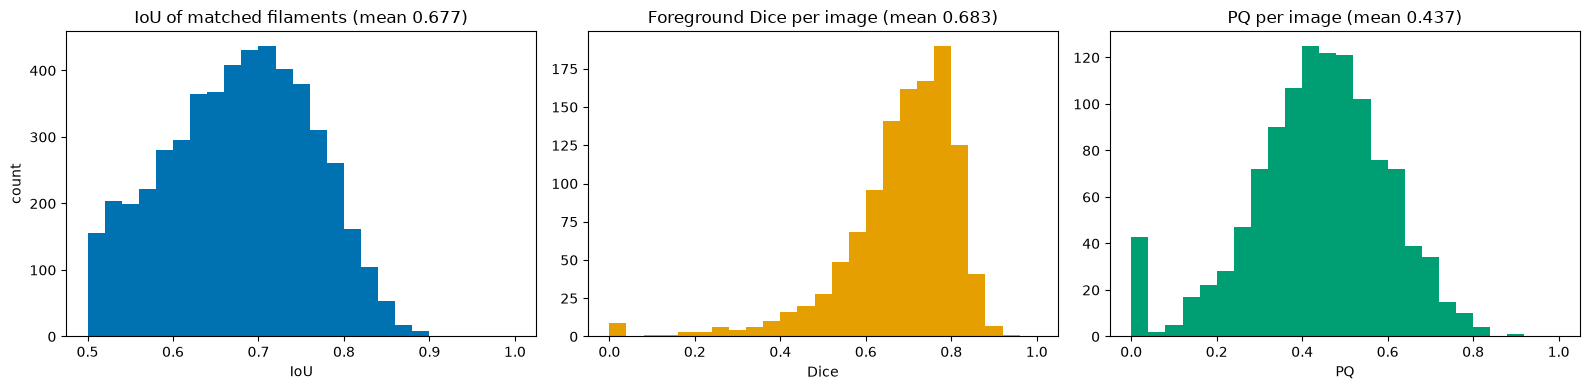

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(acc.matched_ious, bins=np.linspace(0.5, 1, 26), color="#0072B2")
ax[0].set(title=f"IoU of matched filaments (mean {np.mean(acc.matched_ious):.3f})", xlabel="IoU", ylabel="count")
ax[1].hist(acc.per_image_dice, bins=np.linspace(0, 1, 26), color="#E69F00")
ax[1].set(title=f"Foreground Dice per image (mean {np.mean(acc.per_image_dice):.3f})", xlabel="Dice")
ax[2].hist(acc.per_image_pq, bins=np.linspace(0, 1, 26), color="#009E73")
ax[2].set(title=f"PQ per image (mean {np.mean(acc.per_image_pq):.3f})", xlabel="PQ")
plt.tight_layout(); plt.show()

In [14]:
bins = [0, 300, 600, 1000, 2000, 4000, 8000, np.inf]
by_size = gt_df.groupby(pd.cut(gt_df.area, bins), observed=True).agg(filaments=("matched", "size"), recall=("matched", "mean"))
by_conf = pred_df.groupby(pd.cut(pred_df.mean_prob, [0, 0.6, 0.7, 0.8, 0.9, 1.0]), observed=True).agg(
    predictions=("matched", "size"), precision=("matched", "mean"))
cat = gt_df.groupby(gt_df.category.map({1: "Left", 2: "Right", 3: "Unidentifiable", 4: "Ambiguous"})).matched.mean()
display(by_size.round(3), by_conf.round(3), cat.round(3).to_frame("recall"))
print("fragmentation: GT filaments touched by >= 2 predictions:", int((gt_df.n_pred_touching >= 2).sum()))
print("over-merging: predictions touching >= 2 GT filaments:", int((pred_df.n_gt_touching >= 2).sum()))

,filaments,recall
area,,
"(0.0, 300.0]",339,0.153
"(300.0, 600.0]",1390,0.440
"(600.0, 1000.0]",1663,0.637
"(1000.0, 2000.0]",2264,0.689
"(2000.0, 4000.0]",1507,0.709
"(4000.0, 8000.0]",735,0.699
"(8000.0, inf]",301,0.648


,predictions,precision
mean_prob,,
"(0.0, 0.6]",17,0.176
"(0.6, 0.7]",2,0.000
"(0.7, 0.8]",3,0.333
"(0.8, 0.9]",1611,0.482
"(0.9, 1.0]",5792,0.739


,recall
category,
Left,0.679
Right,0.690
Unidentifiable,0.505


fragmentation: GT filaments touched by >= 2 predictions: 319
over-merging: predictions touching >= 2 GT filaments: 251


### 7b. The organisers' self-evaluation analysis

The organisers' public self-evaluation notebook scores every (image, annotator) pair: IoU and Dice of all
overlapping reference/prediction pairs, and the matching cases 1:n (a reference filament overlapped by n predictions,
fragmentation) and n:1 (a prediction overlapping n reference filaments, over-merging). `report/official_eval.py`
reproduces it (same PQ as ours) and adds the annotator-vs-annotator baseline.

In [15]:
import subprocess
subprocess.run([sys.executable, str(ROOT / "report" / "official_eval.py"), "--oof", str(OOF_DIR),
                "--params", str(PARAMS_FILE), "--workers", str(WORKERS)], check=True, cwd=ROOT)
official = json.loads((ROOT / "report" / "official_eval.json").read_text())
pd.DataFrame({k: v for k, v in official.items() if k != "n_images"}).round(3)

,model,annotator_vs_annotator
PQ,0.439,0.340
mean_IoU_overlapping,0.579,0.517
mean_Dice_overlapping,0.711,0.660
gt_hits,6511.000,3297.000
gt_misses,1688.000,707.000
pred_hits,6611.000,3282.000
pred_misses,814.000,713.000
gt_1to1,6192.000,3180.000
gt_1to2plus,319.000,117.000
pred_1to1,6360.000,3146.000


## 8. Test inference, submission and compute cost

Each group's fold models are averaged (8-view TTA each), the groups are blended with the configured weights, the
tuned rules form the instances and the refiner redraws their extent. The decision layer reached the same
out-of-fold PQ as the rules, so the simpler, fully interpretable rules are used. One CSV row per filament:
`filament_id = <image stem>_<k>`, `segmentation_rle` = COCO RLE counts of a 2048 x 2048 mask.
The timings below give the end-to-end cost per 2048 × 2048 image on this machine.

In [16]:
test_stems = sorted(p.stem for p in paths.TEST_IMAGES.glob("*.jpeg"))
timing, specs = {}, []
for g in CFG["groups"]:
    cache = paths.WORK_DIR / "test_probs" / f"group_{g['name']}_{TTA}"
    t0 = time.time()
    predict.main(["--weights", *[str(WEIGHTS[m, f]) for m in g["members"] for f in available], "--tta", TTA,
                  "--prob-cache", str(cache), "--maps-only"])
    timing[g["name"]] = (time.time() - t0) / len(test_stems)
    specs.append((g["weight"], [cache]))
blend_dir = paths.WORK_DIR / "test_probs" / f"pipeline_{MODE}_{TTA}"
blend_dirs(blend_dir, specs)
t0 = time.time()
args = ["--weights", str(WEIGHTS[MEMBERS[0], available[0]]), "--prob-cache", str(blend_dir),
        "--params", str(PARAMS_FILE), "--out", str(SUBMISSION)]
predict.main(args + (["--refiner", str(REFINER_FILE)] if REFINER_FILE else []))
timing["rules + refiner"] = (time.time() - t0) / len(test_stems)
sub = pd.read_csv(SUBMISSION)
stems = sub.filament_id.str.rsplit("_", n=1).str[0]
print(f"{len(sub)} filaments, {stems.nunique()} / {len(test_stems)} images")
assert sub.filament_id.is_unique and set(stems) <= set(test_stems)
print("seconds per image (cached maps are not recomputed; delete work/test_probs to time a cold run):")
print({k: round(v, 2) for k, v in timing.items()}, "| total", round(sum(timing.values()), 2))
sub.head()

post-processing: {'threshold': 0.5, 'merge_gap': 0, 'min_area': 100, 'min_mean_prob': 0.0, 'min_instances': 1}


probability maps for 180 images in D:\Kaggle Solar Filament Segmentation Challenge 2026\work\test_probs\group_effv2_d4


post-processing: {'threshold': 0.5, 'merge_gap': 0, 'min_area': 100, 'min_mean_prob': 0.0, 'min_instances': 1}


probability maps for 180 images in D:\Kaggle Solar Filament Segmentation Challenge 2026\work\test_probs\group_convnext_d4


post-processing: {'threshold': 0.5, 'merge_gap': 0, 'min_area': 100, 'min_mean_prob': 0.0, 'min_instances': 1}


probability maps for 180 images in D:\Kaggle Solar Filament Segmentation Challenge 2026\work\test_probs\group_cnx1536_d4


... (2 outputs left out)

post-processing: {'threshold': 0.5, 'merge_gap': 16, 'min_area': 300, 'min_mean_prob': 0.85, 'min_instances': 1}


refiner: threshold 0.5, cv PQ 0.4434 (rules 0.4390)


wrote 1131 filaments for 180 images to D:\Kaggle Solar Filament Segmentation Challenge 2026\submission_full.csv (93s, 0.52s/image)
1131 filaments, 180 / 180 images
seconds per image (cached maps are not recomputed; delete work/test_probs to time a cold run):
{'effv2': 1.57, 'convnext': 1.73, 'cnx1536': 3.74, 'cnxs': 2.45, 'rules + refiner': 0.52} | total 10.02


,filament_id,segmentation_rle
0,20110120105534Ch_1,d_dh22mo120OXP<0goC201N10001fPNMdn13\QNMen13YQ...
1,20110120105534Ch_2,ojXo13lo10O2O000001O1Mko90WPF2O0000000000Oho?0...
2,20110130110334Ch_1,b_Pe251Odo19M3N5L00000mPN^Ohn1`0VQNCjn1>RQNDon...
3,20110214175414Mh_1,Y]f[26go15L3N1I8N1O2O001N1POXOhRNi0Vm1ZOgRNg0Y...
4,20110214175414Mh_2,i]Pc21oo11N10000O1001N1000O2O0O101O0010O010O01...


## 9. Qualitative examples

Validation images (out-of-fold): annotators in blue / orange / green, model prediction in magenta.

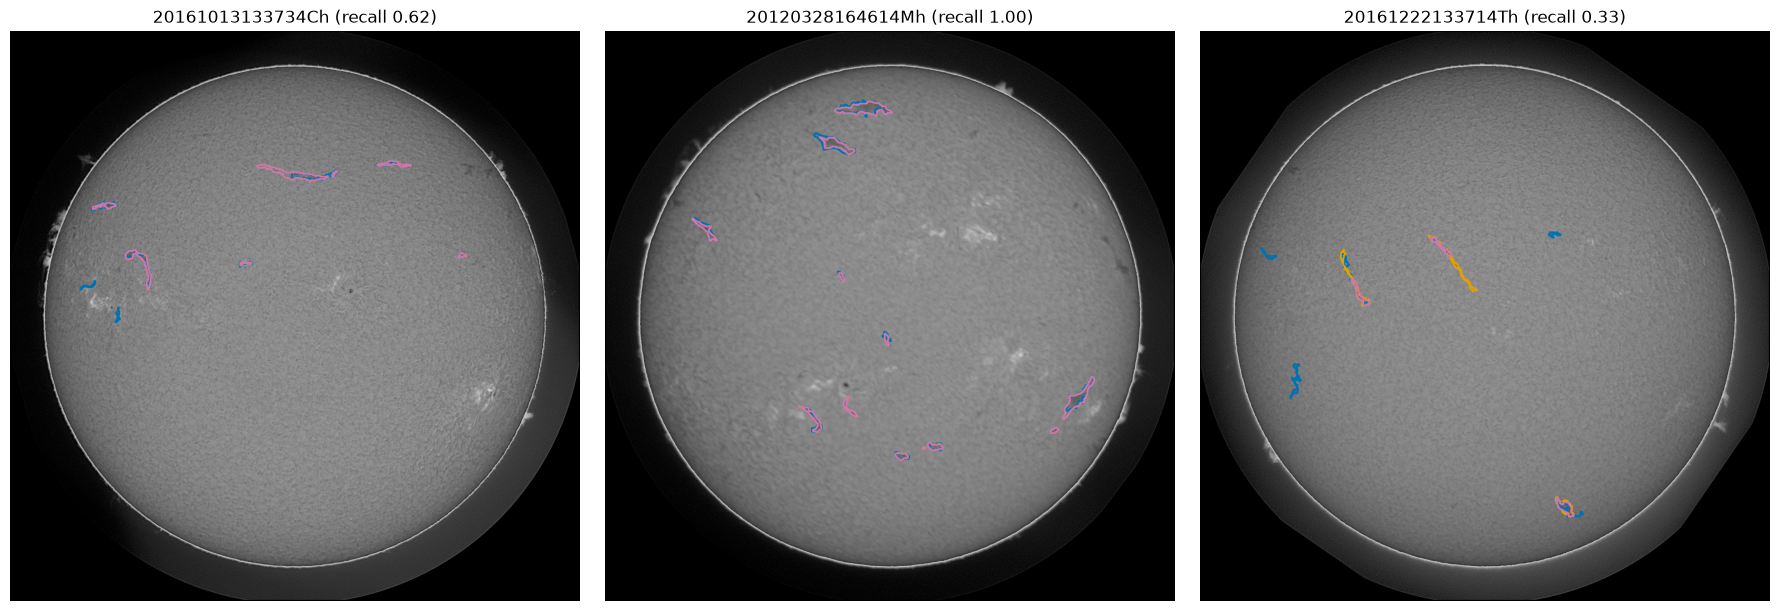

In [17]:
img_recall = gt_df.groupby("image").matched.mean().sort_values()
examples = [img_recall.index[len(img_recall) // 2], img_recall.index[int(len(img_recall) * 0.9)],
            img_recall.index[int(len(img_recall) * 0.1)]]
by_stem = {it.stem: it for it in items}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, stem in zip(axes, examples):
    it = by_stem[stem]
    pred = probs_to_labels(prob_loader(OOF_DIR)(stem), params)
    lmaps = [label_map(f) for f in it.annotations.values()][:3]
    colors = PALETTE[: len(lmaps)] + [PALETTE[3]]
    ax.imshow(outlines(read_gray(paths.TRAIN_IMAGES / it.file_name), lmaps + [pred], colors=colors, scale=0.5))
    ax.set_title(f"{stem} (recall {img_recall[stem]:.2f})"); ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Summary

* Annotators agree with each other only at PQ = 0.34; the model trained on their per-pixel agreement exceeds that
  level out-of-fold (section 7): 0.443 with the tuned rules and the instance refiner.
* Modern encoders (EfficientNetV2-S, ConvNeXt) beat the ResNet-34 / UNet++ ensemble we started from, and more
  models do not automatically help: the instance refiner gains twice as much on the modern-encoder blend. Tuning
  the instance rules directly for PQ and redrawing each instance give most of the gain over a single thresholded
  model; a PQ-optimal decision layer that decides per candidate whether keeping it raises expected PQ performs on
  par with the tuned rules.
* Remaining errors are dominated by (i) small, faint filaments that only some annotators mark and (ii) near misses
  (IoU 0.25-0.5) caused by different filament extent or splitting, the same sources of disagreement seen between
  annotators.